# RutaPro · Notebook 04: Robustez I. Baselines justos, techo del simulador, incertidumbre y sesgos

**Qué es este notebook.** Es una auditoría de rigor del trabajo ya hecho (notebooks 00 a 03). **No cambia el dataset v1 ni los resultados de los notebooks anteriores**: usa exactamente los mismos datos, las mismas particiones y los mismos hiperparámetros, y agrega lo que un jurado exigente suele pedir cuando los datos son simulados.

| Sección | Qué agrega | Por qué importa |
|---|---|---|
| 1 | Verifica que el simulador parametrizable reproduce el dataset v1 al 100 % | Trazabilidad: se puede regenerar y modificar sin perder el v1 |
| 2 | Baselines nuevos: **Aleatorio** (piso) y **Popularidad por segmento** (baseline personalizado simple) | Si un modelo complejo solo supera a la popularidad global, el mérito puede ser la personalización trivial, no el algoritmo |
| 3 | **Oráculo del simulador** (techo) | Dice cuánto margen de mejora existe realmente en estos datos |
| 4 | Intervalos de confianza para **todas** las métricas y semillas promediadas por estudiante | Consistencia estadística: tablas y pruebas usan los mismos números |
| 5 | Pruebas pareadas contra **dos** referencias (popularidad global y el mejor baseline simple) con Holm | Evidencia más exigente que la del notebook 03 |
| 6 | Costo de las reglas de negocio, exposición y equidad por grupo | Pide la Fase 7 del enunciado (riesgo de sesgos) |

> Recordatorio: usuarios e interacciones son **simulados**. Este notebook ayuda a decir con precisión **qué se puede y qué no se puede concluir** de ellos.

In [6]:
import os, sys, subprocess
from google.colab import drive

NECESITA_LIGHTFM = True

# 1) Conectar el Drive y entrar a la carpeta del proyecto
drive.mount('/content/drive')
PROY = "/content/drive/MyDrive/RutaPro"
os.chdir(PROY + "/02_Notebooks")
print("Carpeta actual:", os.getcwd())

# 2) Comprobar que están los archivos imprescindibles
faltan = [f for f in ["rutapro_rec.py", "rutapro_sim.py", "rutapro_extra.py", "rutapro_mooc.py",
                      "resultados/hiperparametros.json", "../01_Datos/cursos.csv",
                      "../01_Datos/pares_usuario_curso.csv"] if not os.path.exists(f)]
print("Archivos que faltan:", faltan if faltan else "ninguno, todo en su sitio")

# 3) LightFM: usa la copia compilada en tu Drive; si no existe, la compila (≈ 2 min) y la guarda
def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-1500:], r.stderr[-1500:])
        raise RuntimeError("Falló: " + cmd[:70])

if NECESITA_LIGHTFM:
    LF = PROY + "/lightfm_src"
    if not os.path.exists(LF + "/lightfm"):
        print("Compilando LightFM, un momento...")
        sh("pip install -q cython")
        sh("rm -rf /content/lightfm_src && git clone -q --depth 1 https://github.com/lyst/lightfm.git /content/lightfm_src")
        p = "/content/lightfm_src/setup.py"
        s = open(p).read()
        s = s.replace("compiler_directives={'language_level' : \"3\"}",
                      "compiler_directives={'language_level': \"3\", 'legacy_implicit_noexcept': True}").replace("-march=native", "-O2")
        open(p, "w").write(s)
        sh("cd /content/lightfm_src && python setup.py cythonize -q && python setup.py build_ext --inplace -q")
        sh("rm -rf '" + LF + "' && cp -r /content/lightfm_src '" + LF + "'")
    sys.path.insert(0, LF)
    import lightfm
    print("LightFM", lightfm.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Carpeta actual: /content/drive/MyDrive/RutaPro/02_Notebooks
Archivos que faltan: ninguno, todo en su sitio
LightFM 1.17


In [7]:
# LightFM debe estar instalado (ver README de notebooks). Si falta, el resto no puede ejecutarse.
try:
    import lightfm
    print("LightFM", lightfm.__version__)
except ImportError as e:
    raise SystemExit("Falta LightFM: instala con 'conda install -c conda-forge lightfm' (ver 02_Notebooks/README).") from e

LightFM 1.17


In [ ]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings("ignore")

import rutapro_rec as rr
import rutapro_sim as sim
import rutapro_extra as ex

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#9a9890"
TXT, TXT2 = "#0b0b0b", "#52514e"
mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d4d3cd", "axes.labelcolor": TXT2, "xtick.color": TXT2, "ytick.color": TXT2,
    "text.color": TXT, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
    "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110,
})
BASE = rr.ruta_base()
DATA = BASE / "01_Datos"
FIG = BASE / "04_Informe" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
RES = BASE / "02_Notebooks" / "resultados_robustez"; RES.mkdir(parents=True, exist_ok=True)
def guardar(fig, n): fig.savefig(FIG / f"{n}.png", dpi=160, bbox_inches="tight")

H = json.loads((BASE / "02_Notebooks" / "resultados" / "hiperparametros.json").read_text())
cursos, usuarios, pares = rr.cargar_datos()
perfil_de = usuarios.set_index("user_id").to_dict("index")
val = rr.construir_particion(cursos, usuarios, pares, etapa="validacion")
prueba = rr.construir_particion(cursos, usuarios, pares, etapa="prueba")
eleg = prueba.usuarios_elegibles()
print(f"Estudiantes evaluables en prueba: {len(eleg)} | hiperparámetros v1: {[k for k in H if k != 'criterio']}")

Estudiantes evaluables en prueba: 133 | hiperparámetros v1: ['Contenido (TF-IDF)', 'KNN usuario', 'KNN ítem', 'LightFM híbrido']


## 1. Trazabilidad: el simulador parametrizable reproduce el v1

El módulo `rutapro_sim.py` es el simulador del notebook 00 reescrito con parámetros. Con los valores originales y `seed = 42` debe producir **los mismos archivos**. Si esto se cumple, cualquier escenario nuevo se puede comparar con el v1 sin dudas sobre qué cambió.

In [ ]:
inter_v1 = pd.read_csv(DATA / "interacciones.csv", parse_dates=["timestamp"])
u_sim, i_sim, traza = sim.generar_dataset(cursos, sim.ParamsSim(), con_traza=True)
pares_re = ex.construir_pares(inter_v1)
pares_v1 = pd.read_csv(DATA / "pares_usuario_curso.csv")

chequeo = pd.Series({
    "usuarios.csv idéntico": bool((u_sim.astype(str).values == pd.read_csv(DATA / "usuarios.csv").astype(str).values).all()),
    "interacciones.csv: mismas filas": i_sim.shape == inter_v1.shape,
    "interacciones.csv: usuario, curso, evento y peso idénticos":
        bool((i_sim[["interaction_id", "user_id", "course_id", "evento", "peso_evento"]].values
              == inter_v1[["interaction_id", "user_id", "course_id", "evento", "peso_evento"]].values).all()),
    "interacciones.csv: fechas idénticas": bool((pd.to_datetime(i_sim.timestamp).values == inter_v1.timestamp.values).all()),
    "interacciones.csv: calificaciones idénticas": bool(np.allclose(i_sim.calificacion.fillna(-1), inter_v1.calificacion.fillna(-1))),
    "pares_usuario_curso.csv reconstruido idéntico (positivo y particiones)":
        bool((pares_re[["user_id", "course_id", "positivo", "particion", "particion_global"]].values
              == pares_v1[["user_id", "course_id", "positivo", "particion", "particion_global"]].values).all()),
})
display(chequeo.to_frame("resultado"))
display(sim.validar(u_sim, i_sim, cursos).to_frame("validación de integridad (v1 regenerado)"))

,resultado
usuarios.csv idéntico,True
interacciones.csv: mismas filas,True
"interacciones.csv: usuario, curso, evento y peso idénticos",True
interacciones.csv: fechas idénticas,True
interacciones.csv: calificaciones idénticas,True
pares_usuario_curso.csv reconstruido idéntico (positivo y particiones),True


,validación de integridad (v1 regenerado)
IDs de usuario únicos,True
IDs de interacción únicos,True
Toda interacción apunta a un usuario existente,True
Toda interacción apunta a un curso existente,True
Calificación solo en finalizaciones,True
Calificación entre 1 y 5,True
Sin eventos antes del registro,True
Inscripción no ocurre sin vista previa,True


**Interpretación.** Las seis comprobaciones dan `True`: `rutapro_sim.py` con los parámetros originales y `seed = 42` regenera **exactamente** el mismo `usuarios.csv`, las mismas interacciones (usuario, curso, evento, peso, fechas y calificaciones) y el mismo `pares_usuario_curso.csv` con sus dos particiones, y el dataset regenerado pasa las 8 validaciones de integridad. Esto significa que el v1 no se toca: es el escenario base y todo lo que se pruebe más adelante (notebooks 05 y 06) se puede comparar contra él sin ambigüedad. También significa que la defensa puede decir que el simulador es **reproducible y está completamente especificado en código**.

## 2. Baselines nuevos y su ajuste justo

Hasta ahora el único baseline era la **popularidad global**. Eso es un rival fácil cuando los datos dependen del perfil. Se agregan dos:

- **Aleatorio:** el piso. Se promedia sobre 20 semillas.
- **Popularidad por segmento:** recomienda lo más inscrito *dentro del grupo del estudiante* (por ejemplo, su objetivo laboral), suavizado con la popularidad global: `puntaje = inscripciones_en_el_segmento + m · proporción_global`. No aprende nada sofisticado: es lo que haría cualquier analista con una tabla dinámica.

Para que la comparación sea justa, el baseline también se **ajusta en validación** (segmento y `m`) con el mismo criterio que los demás modelos: NDCG@10 y regla de parsimonia (tolerancia 0.01).

In [ ]:
TOL = 0.01
filas = []
for cols in [("objetivo_laboral",), ("objetivo_laboral", "nivel"), ("objetivo_laboral", "idioma_preferido"), ("carrera",)]:
    for m in [0, 5, 20, 50, 100]:
        r = rr.evaluar(ex.PopularidadSegmento(cols, m).fit(val), val).loc[10]
        filas.append({"segmento": " + ".join(cols), "n_cols": len(cols), "m": m, **r[["ndcg", "hit_rate", "cobertura"]]})
grid_seg = pd.DataFrame(filas)
cand = grid_seg[grid_seg.ndcg >= grid_seg.ndcg.max() - TOL]
mejor = cand.sort_values(["n_cols", "m"]).iloc[0]          # parsimonia: menos columnas, menor m
COLS, M = tuple(mejor.segmento.split(" + ")), float(mejor.m)
grid_seg.to_csv(RES / "grid_popularidad_segmento.csv", index=False)
display(grid_seg.sort_values("ndcg", ascending=False).head(8).round(3))
print("Elegido (parsimonia):", COLS, "| m =", M, "| NDCG@10 validación =", round(mejor.ndcg, 3))
ref = rr.evaluar(rr.Popularidad().fit(val), val).loc[10, "ndcg"]
print(f"Referencia en validación: Popularidad global = {ref:.3f} | LightFM v1 = 0.198 (notebook 02)")

,segmento,n_cols,m,ndcg,hit_rate,cobertura
0,objetivo_laboral,1,0,0.201,0.361,0.477
1,objetivo_laboral,1,5,0.201,0.346,0.458
2,objetivo_laboral,1,20,0.201,0.346,0.458
3,objetivo_laboral,1,50,0.193,0.338,0.458
11,objetivo_laboral + idioma_preferido,2,5,0.193,0.391,0.607
12,objetivo_laboral + idioma_preferido,2,20,0.193,0.391,0.607
4,objetivo_laboral,1,100,0.192,0.338,0.421
7,objetivo_laboral + nivel,2,20,0.182,0.353,0.654


Elegido (parsimonia): ('objetivo_laboral',) | m = 0.0 | NDCG@10 validación = 0.201


Referencia en validación: Popularidad global = 0.128 | LightFM v1 = 0.198 (notebook 02)


**Interpretación.** El baseline de **popularidad por segmento** se ajustó con las mismas reglas que los demás modelos. Gana el segmento más simple, el **objetivo laboral**, con `m = 0` (sin suavizado hacia la popularidad global), y obtiene un NDCG@10 de **0.201 en validación**: casi idéntico al de LightFM en el notebook 02 (0.198) y mucho más que la popularidad global (0.128). Es decir, **ya en validación un baseline que no aprende nada sofisticado iguala al algoritmo "innovador"**. Esto no invalida el proyecto, pero obliga a cambiar el argumento de defensa: la pregunta correcta ya no es "¿LightFM supera a la popularidad?", sino "¿qué aporta LightFM sobre una personalización simple por objetivo laboral?". Segmentar además por nivel o por idioma no mejora (0.182 y 0.193), lo que es coherente con que esos factores ya los cubren las reglas de negocio.

## 3. Evaluación en prueba con todos los modelos

Protocolo idéntico al notebook 03: reentrenar con entrenamiento + validación, evaluar **una sola vez** en prueba sobre los mismos estudiantes, mismo criterio de relevancia (inscripción), mismo K y sin recomendar lo ya tomado.

Dos cambios de rigor:
1. Los modelos estocásticos (Aleatorio, LightFM) se evalúan con varias semillas y se **promedia por estudiante** (no solo en la tabla). Así las tablas y las pruebas estadísticas usan exactamente los mismos números.
2. Se agrega el **Oráculo**: usa la probabilidad real que el simulador asignó a cada curso en el momento de cada inscripción de prueba. Es el techo: ningún modelo real puede igualarlo porque no conoce el sorteo aleatorio.

Se separan también el efecto de **las reglas de negocio** y el del **algoritmo**: se evalúan *Popularidad + reglas* y *Popularidad por segmento + reglas*, de modo que LightFM + reglas se compara contra rivales que reciben las mismas reglas.

In [ ]:
fab_lfm = lambda s: rr.LightFMHibrido(**H["LightFM híbrido"], seed=s)
con_reglas = lambda m: ex.ConReglas(m, cursos, perfil_de)
hc, hk_u, hk_i = H["Contenido (TF-IDF)"], H["KNN usuario"], H["KNN ítem"]

pop = rr.Popularidad().fit(prueba)
seg = ex.PopularidadSegmento(COLS, M).fit(prueba)
cont = rr.ContenidoTFIDF(ngram=tuple(hc["ngram"]), alpha_perfil=hc["alpha_perfil"], usar_vistas=hc["usar_vistas"]).fit(prueba)
knn_u = rr.KNNColaborativo(k=hk_u["k"], variante="usuario", usar_vistas=hk_u["usar_vistas"]).fit(prueba)
knn_i = rr.KNNColaborativo(k=hk_i["k"], variante="item", usar_vistas=hk_i["usar_vistas"]).fit(prueba)
ora = ex.Oraculo(traza).fit(prueba)
lfm42 = fab_lfm(42).fit(prueba)                      # semilla 42 solo para recomendaciones de ejemplo y exposición

dets, cob, recs = {}, {}, {}
def correr(nombre, modelo, ks=(5, 10)):
    res, det, r = rr.evaluar(modelo, prueba, ks=ks, devolver_detalle=True)
    dets[nombre], cob[nombre], recs[nombre] = det, res["cobertura"].to_dict(), r

det_a, res_a = ex.evaluar_semillas(lambda s: ex.Aleatorio(s), prueba, semillas=range(20))
dets["Aleatorio"] = det_a; cob["Aleatorio"] = res_a.groupby("K").cobertura.mean().to_dict()
correr("Popularidad (global)", pop)
correr("Popularidad + reglas", con_reglas(pop))
correr("Pop. por segmento", seg)
correr("Pop. por segmento + reglas", con_reglas(seg))
correr("Contenido (TF-IDF)", cont)
correr("KNN usuario", knn_u)
correr("KNN ítem", knn_i)
dets["LightFM híbrido"], r_lf = ex.evaluar_semillas(fab_lfm, prueba)
cob["LightFM híbrido"] = r_lf.groupby("K").cobertura.mean().to_dict()
dets["LightFM + reglas"], r_lfr = ex.evaluar_semillas(fab_lfm, prueba, envolver=con_reglas)
cob["LightFM + reglas"] = r_lfr.groupby("K").cobertura.mean().to_dict()
recs["LightFM híbrido"] = rr.evaluar(lfm42, prueba, ks=(10,), devolver_detalle=True)[2]
recs["LightFM + reglas"] = rr.evaluar(con_reglas(lfm42), prueba, ks=(10,), devolver_detalle=True)[2]
correr("Oráculo (techo)", ora)

orden = ["Aleatorio", "Popularidad (global)", "Popularidad + reglas", "Pop. por segmento", "Pop. por segmento + reglas",
         "Contenido (TF-IDF)", "KNN usuario", "KNN ítem", "LightFM híbrido", "LightFM + reglas", "Oráculo (techo)"]
dets = {n: dets[n] for n in orden}
def tabla_principal(K):
    t = ex.tabla_con_ic(dets, K=K)
    t["cobertura"] = pd.Series({n: cob[n][K] for n in orden})
    t["% del techo (NDCG)"] = 100 * t["ndcg"] / t.loc["Oráculo (techo)", "ndcg"]
    return t[["estudiantes", "ndcg", "ndcg IC95", "hit_rate", "hit_rate IC95", "recall", "recall IC95", "precision",
              "cobertura", "% del techo (NDCG)"]]
t10, t5 = tabla_principal(10), tabla_principal(5)
t10.to_csv(RES / "tabla_principal_k10.csv"); t5.to_csv(RES / "tabla_principal_k5.csv")
print("K = 10"); display(t10.round(3))
print("K = 5"); display(t5.round(3))

K = 10


,estudiantes,ndcg,ndcg IC95,hit_rate,hit_rate IC95,recall,recall IC95,precision,cobertura,% del techo (NDCG)
modelo,,,,,,,,,,
Aleatorio,133,0.051,"[0.046, 0.056]",0.149,"[0.132, 0.167]",0.102,"[0.093, 0.112]",0.015,1.000,17.256
Popularidad (global),133,0.134,"[0.101, 0.169]",0.346,"[0.271, 0.429]",0.264,"[0.199, 0.331]",0.039,0.159,45.514
Popularidad + reglas,133,0.132,"[0.100, 0.168]",0.346,"[0.263, 0.429]",0.263,"[0.198, 0.331]",0.039,0.196,44.977
Pop. por segmento,133,0.173,"[0.135, 0.215]",0.436,"[0.353, 0.519]",0.341,"[0.271, 0.414]",0.048,0.542,59.071
Pop. por segmento + reglas,133,0.183,"[0.142, 0.225]",0.444,"[0.361, 0.526]",0.356,"[0.281, 0.431]",0.049,0.570,62.202
Contenido (TF-IDF),133,0.126,"[0.093, 0.161]",0.346,"[0.263, 0.429]",0.254,"[0.190, 0.320]",0.037,0.879,42.829
KNN usuario,133,0.129,"[0.091, 0.172]",0.316,"[0.241, 0.398]",0.229,"[0.168, 0.293]",0.034,0.729,44.002
KNN ítem,133,0.130,"[0.088, 0.175]",0.286,"[0.211, 0.361]",0.210,"[0.150, 0.274]",0.032,1.000,44.161
LightFM híbrido,133,0.199,"[0.156, 0.243]",0.462,"[0.377, 0.541]",0.369,"[0.296, 0.438]",0.052,0.783,67.790


K = 5


,estudiantes,ndcg,ndcg IC95,hit_rate,hit_rate IC95,recall,recall IC95,precision,cobertura,% del techo (NDCG)
modelo,,,,,,,,,,
Aleatorio,133,0.031,"[0.027, 0.036]",0.070,"[0.061, 0.081]",0.047,"[0.041, 0.054]",0.014,0.998,13.258
Popularidad (global),133,0.102,"[0.070, 0.136]",0.233,"[0.165, 0.308]",0.174,"[0.119, 0.233]",0.051,0.103,43.190
Popularidad + reglas,133,0.095,"[0.064, 0.129]",0.218,"[0.150, 0.286]",0.159,"[0.107, 0.216]",0.047,0.112,40.299
Pop. por segmento,133,0.115,"[0.078, 0.157]",0.233,"[0.165, 0.308]",0.175,"[0.120, 0.236]",0.050,0.393,48.918
Pop. por segmento + reglas,133,0.124,"[0.084, 0.166]",0.241,"[0.173, 0.316]",0.190,"[0.130, 0.253]",0.051,0.421,52.665
Contenido (TF-IDF),133,0.088,"[0.057, 0.122]",0.203,"[0.135, 0.278]",0.148,"[0.096, 0.207]",0.042,0.617,37.341
KNN usuario,133,0.098,"[0.062, 0.139]",0.203,"[0.143, 0.271]",0.140,"[0.092, 0.195]",0.041,0.579,41.615
KNN ítem,133,0.109,"[0.068, 0.155]",0.203,"[0.135, 0.278]",0.155,"[0.102, 0.213]",0.044,0.944,46.371
LightFM híbrido,133,0.153,"[0.112, 0.196]",0.313,"[0.238, 0.389]",0.241,"[0.179, 0.304]",0.065,0.643,64.958


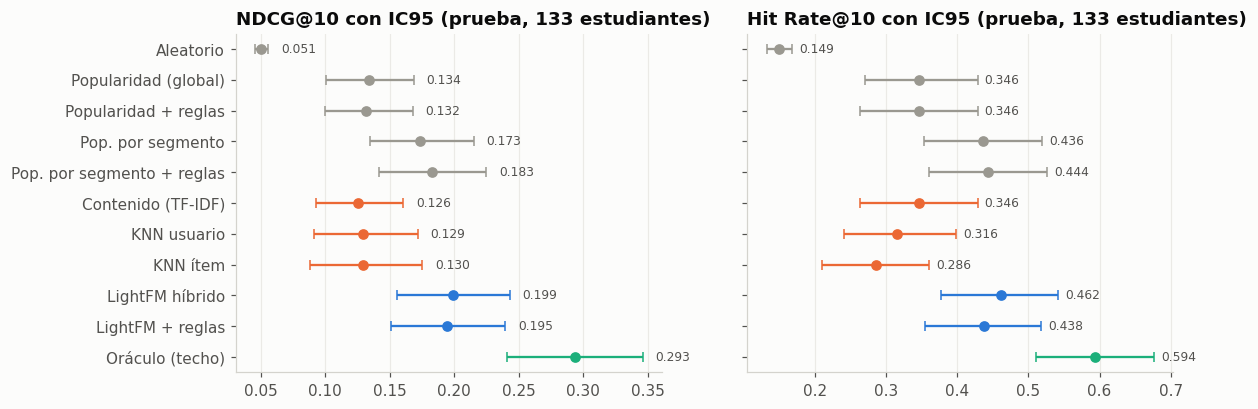

In [ ]:
# Gráfico: NDCG@10 y Hit Rate@10 con IC95 (remuestreo de estudiantes)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
y = np.arange(len(orden))[::-1]
for ax, met, tit in zip(axes, ["ndcg", "hit_rate"], ["NDCG@10", "Hit Rate@10"]):
    for yi, n in zip(y, orden):
        mu, lo, hi = ex.ic_bootstrap(dets[n].query("K == 10")[met].values)
        col = GRIS if "Popularidad" in n or n.startswith("Pop.") or n == "Aleatorio" else (AZUL if "LightFM" in n else NARANJA)
        if n.startswith("Oráculo"): col = AQUA
        ax.errorbar(mu, yi, xerr=[[mu - lo], [hi - mu]], fmt="o", color=col, ecolor=col, capsize=3, ms=6)
        ax.text(hi + 0.01, yi, f"{mu:.3f}", va="center", fontsize=8, color=TXT2)
    ax.set_title(f"{tit} con IC95 (prueba, {len(eleg)} estudiantes)"); ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, orden)
guardar(fig, "19_ic_modelos"); plt.show()

**Interpretación.**

- **Piso y techo.** Con K = 10, recomendar al azar da un NDCG@10 de 0.051, y el **oráculo** (que conoce las reglas exactas del simulador y el estado de cada estudiante, pero no el sorteo aleatorio) llega a **0.293 con Hit Rate de 59 %**. Ese es el techo real de estos datos: incluso quien conoce el mecanismo acierta al menos un curso para solo 6 de cada 10 estudiantes, porque la elección simulada tiene un 15 % de exploración al azar y una selección probabilística (temperatura 0.6). Que LightFM no llegue a 0.30 no es un defecto del modelo.
- **Cuánto del techo alcanza cada modelo.** LightFM + reglas llega al **66 %** del techo (0.195), Popularidad por segmento + reglas al **62 %** (0.183), la popularidad global al 45 % (0.134) y contenido y KNN al 43 a 44 %.
- **Incertidumbre.** Los IC95 de los mejores modelos se **solapan mucho**: LightFM + reglas [0.151, 0.239] frente a Popularidad por segmento + reglas [0.142, 0.225]. Con 133 estudiantes, las diferencias entre los tres mejores modelos son pequeñas frente al error de estimación.
- **Efecto de las reglas.** Aplicadas a la popularidad global no cambian nada (0.134 a 0.132). Aplicadas al baseline por segmento suben de 0.173 a 0.183, y aplicadas a LightFM bajan de 0.199 a 0.195, dentro del error. Las reglas son prácticamente neutras en precisión.
- **Cobertura.** Popularidad global 16 %, por segmento + reglas 57 %, LightFM + reglas 79 %.

Con K = 5 el panorama es parecido: LightFM + reglas 0.154, por segmento + reglas 0.124, popularidad global 0.102, techo 0.235.

## 4. Pruebas pareadas contra dos referencias

Para cada estudiante se compara el NDCG@10 (promediado entre semillas cuando corresponde) de cada modelo contra **dos** referencias:

- **A. Popularidad global.** Es lo que se hizo en el notebook 03.
- **B. Popularidad por segmento + reglas.** El rival más duro que se puede construir sin aprender nada. Si un algoritmo complejo no lo supera, la ventaja es de personalización y no del algoritmo.

Se usa Wilcoxon de rangos con signo (la mayoría de valores es 0), IC95 bootstrap de la diferencia media y corrección de Holm **dentro de cada familia**.

In [ ]:
def familia(base, candidatos, K=10):
    t = pd.DataFrame({n: ex.comparar_pareado(dets[n], dets[base], K=K) for n in candidatos}).T
    t["p ajustado (Holm)"] = ex.holm(t["p (Wilcoxon)"].astype(float))
    t["¿significativo al 5 %?"] = np.where(t["p ajustado (Holm)"] < 0.05, "sí", "no")
    return t
cand_A = [n for n in orden if n not in ("Aleatorio", "Popularidad (global)", "Oráculo (techo)")]
cand_B = ["Contenido (TF-IDF)", "KNN usuario", "KNN ítem", "LightFM híbrido", "LightFM + reglas", "Pop. por segmento"]
fam_A = familia("Popularidad (global)", cand_A)
fam_B = familia("Pop. por segmento + reglas", cand_B)
fam_A.to_csv(RES / "pruebas_vs_popularidad_global.csv"); fam_B.to_csv(RES / "pruebas_vs_pop_segmento_reglas.csv")
print("A. Diferencia de NDCG@10 frente a la Popularidad global"); display(fam_A.round(4))
print("B. Diferencia de NDCG@10 frente a Popularidad por segmento + reglas"); display(fam_B.round(4))

# Misma comparación con K = 5 (el enunciado pide analizar al menos dos valores de K)
fam_A5 = familia("Popularidad (global)", cand_A, K=5)
fam_B5 = familia("Pop. por segmento + reglas", cand_B, K=5)
fam_A5.to_csv(RES / "pruebas_vs_popularidad_global_k5.csv"); fam_B5.to_csv(RES / "pruebas_vs_pop_segmento_reglas_k5.csv")
print("K = 5 · A. frente a Popularidad global"); display(fam_A5.round(4))
print("K = 5 · B. frente a Popularidad por segmento + reglas"); display(fam_B5.round(4))

# ¿Qué diferencia puede detectar esta muestra? (potencia 80 %, nivel 5 %, prueba pareada aproximada)
d = (dets["LightFM + reglas"].query("K == 10").set_index("user_id")["ndcg"]
     - dets["Pop. por segmento + reglas"].query("K == 10").set_index("user_id")["ndcg"])
se = d.std(ddof=1) / np.sqrt(len(d))
mde = (1.96 + 0.84) * se
print(f"Desviación de la diferencia por estudiante = {d.std(ddof=1):.3f} | error estándar = {se:.4f}")
print(f"Diferencia mínima detectable (potencia 80 %, nivel 5 %) ≈ {mde:.3f} de NDCG@10 con {len(d)} estudiantes")

A. Diferencia de NDCG@10 frente a la Popularidad global


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
Popularidad + reglas,-0.0016,-0.0115,0.0077,8.0,5.0,0.8259,1.0000,no
Pop. por segmento,0.0398,0.0031,0.0771,37.0,30.0,0.0347,0.1735,no
Pop. por segmento + reglas,0.0490,0.0108,0.0871,39.0,27.0,0.0116,0.0696,no
Contenido (TF-IDF),-0.0079,-0.0550,0.0395,35.0,37.0,0.7490,1.0000,no
KNN usuario,-0.0044,-0.0424,0.0348,27.0,28.0,0.6998,1.0000,no
KNN ítem,-0.0040,-0.0489,0.0424,29.0,32.0,0.6560,1.0000,no
LightFM híbrido,0.0654,0.0236,0.1078,55.0,21.0,0.0006,0.0048,sí
LightFM + reglas,0.0610,0.0180,0.1043,54.0,21.0,0.0018,0.0127,sí


B. Diferencia de NDCG@10 frente a Popularidad por segmento + reglas


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
Contenido (TF-IDF),-0.0569,-0.1047,-0.0098,31.0,47.0,0.0272,0.1358,no
KNN usuario,-0.0534,-0.0966,-0.0119,28.0,43.0,0.0120,0.0718,no
KNN ítem,-0.0530,-0.1053,-0.0004,27.0,45.0,0.0694,0.2777,no
LightFM híbrido,0.0164,-0.0157,0.0482,43.0,31.0,0.3268,0.6537,no
LightFM + reglas,0.0121,-0.0191,0.0438,40.0,32.0,0.5097,0.6537,no
Pop. por segmento,-0.0092,-0.0254,0.0065,9.0,21.0,0.1711,0.5134,no


K = 5 · A. frente a Popularidad global


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
Popularidad + reglas,-0.0068,-0.0165,0.0018,1.0,4.0,0.1875,1.0000,no
Pop. por segmento,0.0135,-0.0213,0.0485,21.0,17.0,0.5184,1.0000,no
Pop. por segmento + reglas,0.0223,-0.0146,0.0596,23.0,18.0,0.2432,1.0000,no
Contenido (TF-IDF),-0.0138,-0.0601,0.0331,22.0,25.0,0.4642,1.0000,no
KNN usuario,-0.0037,-0.0402,0.0334,20.0,18.0,0.7495,1.0000,no
KNN ítem,0.0075,-0.0331,0.0513,23.0,20.0,0.9855,1.0000,no
LightFM híbrido,0.0513,0.0120,0.0900,42.0,14.0,0.0022,0.0178,sí
LightFM + reglas,0.0523,0.0120,0.0921,43.0,14.0,0.0028,0.0194,sí


K = 5 · B. frente a Popularidad por segmento + reglas


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
Contenido (TF-IDF),-0.0361,-0.0843,0.0124,20.0,29.0,0.1938,0.5882,no
KNN usuario,-0.0260,-0.0688,0.0152,19.0,21.0,0.1445,0.5882,no
KNN ítem,-0.0148,-0.0675,0.0384,23.0,24.0,0.4209,0.5882,no
LightFM híbrido,0.0289,-0.0049,0.0641,32.0,19.0,0.1121,0.5882,no
LightFM + reglas,0.0300,-0.0041,0.0652,32.0,19.0,0.0980,0.5882,no
Pop. por segmento,-0.0088,-0.0223,0.0029,2.0,8.0,0.1523,0.5882,no


Desviación de la diferencia por estudiante = 0.187 | error estándar = 0.0162
Diferencia mínima detectable (potencia 80 %, nivel 5 %) ≈ 0.045 de NDCG@10 con 133 estudiantes


**Interpretación.**

**A. Frente a la popularidad global (K = 10).** LightFM puro mejora el NDCG@10 en +0.065 (IC95 de +0.024 a +0.108; p ajustado por Holm = 0.005) y LightFM + reglas en +0.061 (IC95 +0.018 a +0.104; p ajustado = 0.013), con 54 estudiantes que mejoran frente a 21 que empeoran. Con K = 5 sigue siendo significativo (p ajustado de 0.018 y 0.019). Es la misma conclusión del notebook 03, pero ahora con semillas promediadas por estudiante y sin depender de una sola semilla. Contenido y los dos KNN no se distinguen de la popularidad global (p ajustado = 1.0). La popularidad por segmento tampoco es significativa tras Holm (p ajustado = 0.17 sin reglas y 0.070 con reglas en K = 10), aunque su estimación puntual es positiva.

**B. Frente a Popularidad por segmento + reglas.**
- LightFM + reglas mejora en solo **+0.012** de NDCG@10 (IC95 de −0.019 a +0.044; p ajustado = 0.65; mejora a 40 estudiantes y empeora a 32). LightFM puro: +0.016 (IC95 de −0.016 a +0.048).
- Con K = 5 la diferencia es mayor (+0.030; IC95 de −0.004 a +0.065) pero tampoco significativa (p sin ajustar = 0.098; p ajustado = 0.59).
- Contenido y KNN quedan **por debajo** del baseline por segmento en la estimación puntual (−0.053 a −0.057 en K = 10). Antes de la corrección de Holm, contenido y KNN usuario sí quedan por debajo (p = 0.027 y 0.012). Tras Holm ya no, así que hay que describirlo como una tendencia y no como una conclusión.

**Poder estadístico.** La desviación de la diferencia por estudiante es 0.187, por lo que con 133 estudiantes la diferencia mínima detectable (potencia 80 %, nivel 5 %) es ≈ **0.045** de NDCG@10. La ventaja observada de LightFM sobre el baseline por segmento (0.012) es unas cuatro veces menor. **Con estos datos no se puede afirmar ni que LightFM supera al baseline por segmento ni que lo iguala**: la muestra simplemente no tiene resolución para distinguirlos.

**Qué se puede defender:** "LightFM + reglas supera significativamente a la popularidad global y alcanza el 66 % del techo del simulador. Frente a una personalización simple por objetivo laboral la diferencia es pequeña (+0.012) y no concluyente con 133 estudiantes."

## 5. Sensibilidad a K (con los baselines nuevos y el techo)

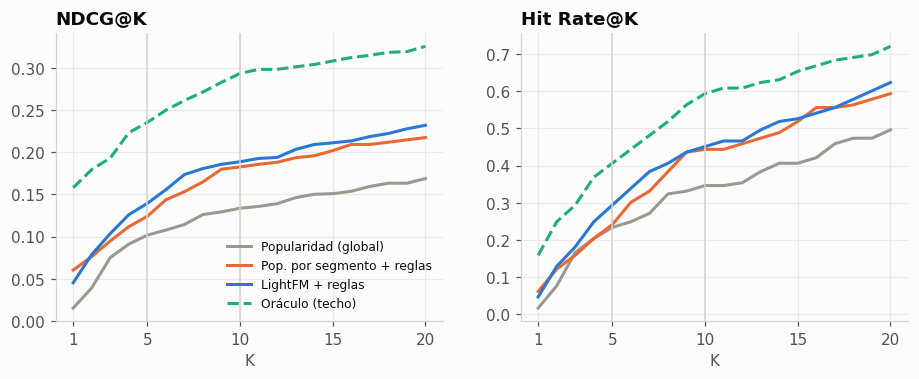

K,3,5,10
Popularidad (global),0.075,0.102,0.134
Pop. por segmento + reglas,0.095,0.124,0.183
LightFM + reglas,0.103,0.139,0.189
Oráculo (techo),0.193,0.235,0.293


In [ ]:
KS = range(1, 21)
curvas = {}
for n, mod in [("Popularidad (global)", pop), ("Pop. por segmento + reglas", con_reglas(seg)),
               ("LightFM + reglas", con_reglas(lfm42)), ("Oráculo (techo)", ora)]:
    curvas[n] = rr.evaluar(mod, prueba, ks=KS)
cols_c = {"Popularidad (global)": GRIS, "Pop. por segmento + reglas": NARANJA, "LightFM + reglas": AZUL, "Oráculo (techo)": AQUA}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, met, tit in zip(axes, ["ndcg", "hit_rate"], ["NDCG@K", "Hit Rate@K"]):
    for n, r in curvas.items():
        ax.plot(r.index, r[met], lw=2, color=cols_c[n], label=n, ls="--" if n.startswith("Oráculo") else "-")
    for k_ in (5, 10): ax.axvline(k_, color="#d4d3cd", lw=1)
    ax.set_title(tit); ax.set_xlabel("K"); ax.set_xticks([1, 5, 10, 15, 20])
axes[0].legend(frameon=False, fontsize=8)
guardar(fig, "20_sensibilidad_k_robustez"); plt.show()
(pd.DataFrame({n: r.loc[[3, 5, 10], "ndcg"] for n, r in curvas.items()}).T).round(3)

**Interpretación.** La ordenación se mantiene para cualquier K: **oráculo > LightFM + reglas ≥ Popularidad por segmento + reglas > Popularidad global**. Con K = 3, 5 y 10 el NDCG de LightFM + reglas (semilla 42) es 0.103, 0.139 y 0.189, el del baseline por segmento 0.095, 0.124 y 0.183, y el de la popularidad global 0.075, 0.102 y 0.134. La ventaja de LightFM sobre el baseline por segmento es chica en todo el rango (entre 0.006 y 0.015) y la del baseline por segmento sobre la popularidad global es de 0.02 a 0.05. El Hit Rate sigue la misma lógica. Como en el notebook 03, K = 10 sigue siendo una elección razonable (se revisa en una pantalla y el NDCG deja de crecer tan rápido), pero ahora queda claro que la brecha respecto del techo (0.29 en K = 10) es mucho mayor que la brecha entre los tres mejores modelos.

## 6. Fase 7: riesgo de sesgos y equidad

El enunciado pide interpretar el **riesgo de sesgos**. Se miden cuatro cosas:

1. **Costo de las reglas de negocio:** de las inscripciones reales de prueba, ¿cuántas quedan vetadas por la regla de idioma y de nivel? Es el recall máximo que se pierde por diseño.
2. **Concentración de la exposición** (sesgo de popularidad): cobertura, Gini de la exposición y qué parte de las recomendaciones cae en el 20 % de cursos más populares.
3. **Equidad por grupo:** ¿el sistema funciona parecido para todas las carreras, niveles, idiomas y objetivos?
4. **Historial corto:** ¿ayuda más a quien tiene menos datos?

In [ ]:
perd = ex.perdida_por_reglas(prueba, perfil_de, cursos)
perd.to_csv(RES / "perdida_por_reglas.csv")
print("1. Inscripciones reales de prueba vetadas por las reglas de idioma y nivel"); display(perd.round(1))

mods_exp = {"Popularidad (global)": recs["Popularidad (global)"], "Pop. por segmento + reglas": recs["Pop. por segmento + reglas"],
            "Contenido (TF-IDF)": recs["Contenido (TF-IDF)"], "KNN ítem": recs["KNN ítem"],
            "LightFM híbrido": recs["LightFM híbrido"], "LightFM + reglas": recs["LightFM + reglas"]}
expo = pd.DataFrame({n: ex.exposicion(r, prueba) for n, r in mods_exp.items()}).T
expo.to_csv(RES / "exposicion.csv")
print("2. Concentración de la exposición (Top-10, semilla 42 para LightFM)"); display(expo.round(2))

1. Inscripciones reales de prueba vetadas por las reglas de idioma y nivel


,inscripciones_prueba,vetadas,% vetado
idioma_preferido,,,
es,67,12,17.9
es+en,132,5,3.8
Todos,199,17,8.5


2. Concentración de la exposición (Top-10, semilla 42 para LightFM)


,cobertura,Gini de exposición,% recs en el 20 % más popular
Popularidad (global),0.16,0.89,100.00
Pop. por segmento + reglas,0.57,0.69,63.68
Contenido (TF-IDF),0.88,0.51,26.39
KNN ítem,1.00,0.35,35.64
LightFM híbrido,0.79,0.56,54.36
LightFM + reglas,0.80,0.56,53.76


In [ ]:
n_hist = prueba.train[prueba.train.positivo == 1].groupby("user_id").size()
info = usuarios.set_index("user_id").loc[eleg].copy()
info["historial"] = pd.cut(n_hist.reindex(info.index), [0, 4, 8, 100], labels=["corto (≤4)", "medio (5-8)", "largo (>8)"]).astype(str)
info = info.reset_index()
grupos = {}
for col in ["carrera", "nivel", "idioma_preferido", "objetivo_laboral", "historial"]:
    tabs = {}
    for n in ["Popularidad (global)", "Pop. por segmento + reglas", "LightFM + reglas"]:
        d = dets[n].query("K == 10").merge(info[["user_id", col]], on="user_id")
        tabs[n] = d.groupby(col)["ndcg"].mean()
    t = pd.DataFrame(tabs); t["estudiantes"] = info.groupby(col).size()
    t["LightFM+reglas − Pop.segmento+reglas"] = t["LightFM + reglas"] - t["Pop. por segmento + reglas"]
    grupos[col] = t
    print(f"3. NDCG@10 por {col}"); display(t.round(3))
pd.concat(grupos, names=["variable", "grupo"]).to_csv(RES / "equidad_por_grupo.csv")

3. NDCG@10 por carrera


,Popularidad (global),Pop. por segmento + reglas,LightFM + reglas,estudiantes,LightFM+reglas − Pop.segmento+reglas
carrera,,,,,
Administración,0.202,0.163,0.144,24,-0.019
Economía,0.079,0.130,0.184,27,0.053
Estadística e Informática,0.162,0.219,0.241,33,0.022
Ingeniería Industrial,0.123,0.187,0.196,25,0.009
Ingeniería de Sistemas,0.098,0.206,0.192,24,-0.014


3. NDCG@10 por nivel


,Popularidad (global),Pop. por segmento + reglas,LightFM + reglas,estudiantes,LightFM+reglas − Pop.segmento+reglas
nivel,,,,,
Avanzado,0.165,0.267,0.238,29,-0.028
Básico,0.107,0.145,0.158,44,0.013
Intermedio,0.138,0.169,0.200,60,0.031


3. NDCG@10 por idioma_preferido


,Popularidad (global),Pop. por segmento + reglas,LightFM + reglas,estudiantes,LightFM+reglas − Pop.segmento+reglas
idioma_preferido,,,,,
es,0.202,0.262,0.264,48,0.002
es+en,0.095,0.138,0.156,85,0.018


3. NDCG@10 por objetivo_laboral


,Popularidad (global),Pop. por segmento + reglas,LightFM + reglas,estudiantes,LightFM+reglas − Pop.segmento+reglas
objetivo_laboral,,,,,
Analista Financiero,0.091,0.076,0.138,23,0.062
BI Analyst,0.083,0.154,0.175,19,0.021
Data Analyst,0.259,0.243,0.245,32,0.002
Data Scientist,0.071,0.151,0.150,20,-0.001
Marketing Analyst,0.165,0.219,0.225,16,0.006
Project Analyst,0.075,0.231,0.215,23,-0.016


3. NDCG@10 por historial


,Popularidad (global),Pop. por segmento + reglas,LightFM + reglas,estudiantes,LightFM+reglas − Pop.segmento+reglas
historial,,,,,
corto (≤4),0.116,0.208,0.223,48,0.016
largo (>8),0.155,0.133,0.143,18,0.010
medio (5-8),0.140,0.178,0.188,67,0.010


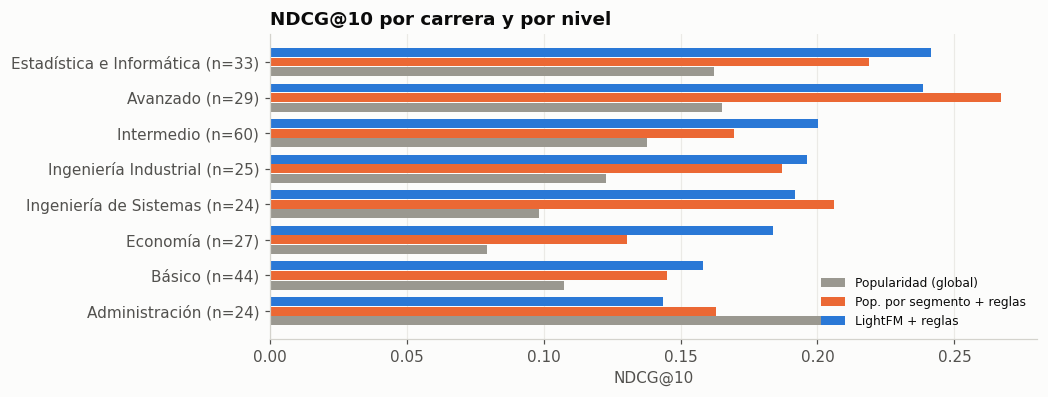

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.6))
t = pd.concat([grupos["carrera"], grupos["nivel"]]).sort_values("LightFM + reglas")
y = np.arange(len(t)); h = 0.27
for j, (n, c) in enumerate([("Popularidad (global)", GRIS), ("Pop. por segmento + reglas", NARANJA), ("LightFM + reglas", AZUL)]):
    ax.barh(y + (j - 1) * h, t[n], height=h - 0.02, color=c, label=n)
ax.set_yticks(y, [f"{i} (n={int(t.loc[i, 'estudiantes'])})" for i in t.index])
ax.set_title("NDCG@10 por carrera y por nivel"); ax.set_xlabel("NDCG@10"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
guardar(fig, "21_equidad_carrera_nivel"); plt.show()

**Interpretación.**

**1. Costo de las reglas.** De las 199 inscripciones reales de prueba, **17 (8.5 %) quedan vetadas** por las reglas de idioma y nivel. Entre los estudiantes que solo estudian en español son **12 de 67 (17.9 %)**: en el simulador esos estudiantes toman un 13 % de cursos en inglés (se asume que usan los subtítulos), y las reglas nunca los recomiendan. A pesar de ello, el efecto sobre las métricas es pequeño (NDCG@10 de 0.199 a 0.195; Hit Rate de 46.2 % a 43.8 %), porque esos cursos rara vez habrían entrado en un Top-10. Es un **riesgo de negocio real**: si en la vida real muchos estudiantes sí usan subtítulos, las reglas ocultarían opciones valiosas. La app ya permite desactivarlas, y conviene decirlo en la defensa.

**2. Concentración de la exposición (sesgo de popularidad).**
- Popularidad global: cobertura 16 %, Gini de exposición 0.89 y 100 % de las recomendaciones en el 20 % de cursos más populares.
- Popularidad por segmento + reglas: cobertura 57 %, Gini 0.69, 64 %.
- LightFM + reglas: cobertura 80 %, Gini 0.56, 54 %.
- KNN ítem tiene la mayor cobertura (100 %) y el menor Gini (0.35) pero con menor acierto; contenido tiene 88 %, Gini 0.51 y solo 26 % en el top popular, pero ignora el idioma.

LightFM + reglas ofrece el mejor equilibrio entre acierto y diversidad de exposición, aunque **más de la mitad de sus recomendaciones sigue siendo de cursos populares**: el sesgo de popularidad se reduce, no desaparece.

**3. Equidad por grupo (NDCG@10 de LightFM + reglas).**
- *Carrera:* Estadística e Informática 0.241 (n = 33), Ing. Industrial 0.196 (25), Ing. de Sistemas 0.192 (24), Economía 0.184 (27) y **Administración 0.144 (24)**. Administración es la carrera con peor desempeño y la única donde la popularidad global (0.202) supera tanto a LightFM + reglas como al baseline por segmento (0.163). Con n = 24 no es concluyente, pero es la señal de equidad que más conviene revisar.
- *Nivel:* Avanzado 0.238 (n = 29), Intermedio 0.200 (60), Básico 0.158 (44). El nivel Avanzado es el único donde el baseline por segmento (0.267) supera a LightFM.
- *Idioma:* solo español 0.264 (n = 48) frente a español e inglés 0.156 (85). Quienes leen ambos idiomas tienen más cursos plausibles, así que acertar es más difícil.
- *Historial:* corto (≤ 4 inscripciones) 0.223 (n = 48), largo (> 8) 0.143 (18). Con historial largo la popularidad global (0.155) queda nominalmente por encima de LightFM.
- Las diferencias entre LightFM + reglas y el baseline por segmento dentro de cada grupo quedan entre −0.03 y +0.06, y **ningún grupo tiene muestra suficiente para concluir algo** (de 16 a 85 estudiantes por grupo). Esto es una advertencia, no un resultado.

## 7. Conclusiones de la auditoría

**Lo que la evidencia sostiene**
1. **LightFM + reglas supera significativamente a la popularidad global** (NDCG@10 +0.061; IC95 de +0.018 a +0.104; p ajustado = 0.013; también con K = 5). Es el único modelo que lo logra.
2. **Alcanza alrededor del 66 % del techo del simulador** (oráculo: NDCG@10 = 0.293; Hit Rate 59 %). El margen de mejora es limitado por el azar del propio simulador.
3. **Es el modelo con mejor equilibrio** entre acierto, cobertura (80 %), concentración de la exposición (Gini 0.56) y cumplimiento de las reglas de idioma y nivel (0 % de infracciones).

**Lo que la evidencia NO sostiene**
4. Que LightFM supere a una personalización simple. Frente a **Popularidad por segmento + reglas** la ventaja es de +0.012 en K = 10 y +0.030 en K = 5, ambas no significativas, con una diferencia mínima detectable de ≈ 0.045. Ya en validación el baseline por segmento igualaba a LightFM (0.201 frente a 0.198).
5. Que contenido y KNN sean competitivos. Quedan en 43 a 44 % del techo, nominalmente por debajo de la popularidad por segmento.
6. Equidad entre grupos: los tamaños de muestra por grupo (16 a 85) no permiten concluir. Administración (n = 24) es la señal de alerta a revisar.

**Cómo conviene presentarlo ante el jurado**
- Decir que el baseline por segmento es el rival más exigente que se pudo construir y que se incluyó **a propósito** para no inflar la ventaja del modelo.
- Justificar la selección de LightFM + reglas no solo por NDCG sino por **cobertura, menor concentración, uso del historial y manejo del cold start**, y reconocer que una popularidad por objetivo laboral es una alternativa más barata y explicable. El enunciado dice expresamente que la selección no tiene que recaer en el modelo más complejo.
- Reconocer que **los datos simulados dependen del perfil del estudiante**, lo cual beneficia a cualquier método que lo use, incluido el baseline por segmento. Los notebooks 05 y 06 miden cuánto cambia esto bajo otros supuestos del simulador.

**Cambios que hay que reflejar en los documentos del proyecto:** agregar los baselines Aleatorio y Popularidad por segmento a la tabla del informe; reportar IC95 para todas las métricas; incluir el techo del oráculo; y actualizar la afirmación sobre las reglas ("sin pérdida" por "pérdida pequeña: 8.5 % de las inscripciones de prueba vetadas, 17.9 % para quienes solo estudian en español").

In [ ]:
print("Archivos generados en", RES.relative_to(BASE))
for p in sorted(RES.iterdir()): print(" -", p.name)

Archivos generados en 02_Notebooks/resultados_robustez
 - _cache
 - cold_start_A_k10.csv
 - cold_start_A_k5.csv
 - cold_start_B_k10.csv
 - cold_start_B_k5.csv
 - cold_start_pruebas_A1_k10.csv
 - cold_start_pruebas_A1_k5.csv
 - cold_start_pruebas_A2_k10.csv
 - cold_start_pruebas_A2_k5.csv
 - cold_start_pruebas_B1_k10.csv
 - cold_start_pruebas_B1_k5.csv
 - cold_start_pruebas_B2_k10.csv
 - cold_start_pruebas_B2_k5.csv
 - equidad_por_grupo.csv
 - exposicion.csv
 - grid_popularidad_segmento.csv
 - perdida_por_reglas.csv
 - plausibilidad_escenarios.csv
 - pruebas_vs_pop_segmento_reglas.csv
 - pruebas_vs_pop_segmento_reglas_k5.csv
 - pruebas_vs_popularidad_global.csv
 - pruebas_vs_popularidad_global_k5.csv
 - replicas_comparaciones_global.csv
 - replicas_diferencias.csv
 - replicas_efecto_fuga.csv
 - replicas_hiperparametros.json
 - replicas_ndcg_global.csv
 - replicas_pct_techo_global.csv
 - replicas_resultados.csv
 - replicas_robustez_eleccion.csv
 - tabla_principal_k10.csv
 - tabla_princip